In [1]:
# Only in Colab: work inside the homework folder of Drive (the .py files are there)
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir("/content/drive/MyDrive/POSGRADOS/HUNGRIA/MASTER/1/FNANCIAL PROCESS /HOMEWORKS/2_HW_LECTURE_4")
except ImportError:
    pass
print(os.getcwd())

/home/claude/hw2task/final


**Homework 2: Implement calibrator for Tree. Part 2: Task. Q4: pictures of the calibrated trees**

*Make simple plots to illustrate results.*

For the contract of Demo A, the up step is calibrated (`calibrate`, Q1) and the two trees of the lecture code are drawn: the spot tree (`create_spot_tree`, cell 5) and the price tree (`create_discounted_price_tree`, cell 8). $x$ = time step $t$, $y$ = spot $S$, colour = node value $V$ (discounted to $t = 0$; the root is the price).

**NEW CODE** (file `tree_plot.py`): `calibrated_trees` (calibrate + the two lecture trees), `important_nodes`, `plot_tree`; imported with the code of Q1 and Homework 1

In [2]:
# Q4: the calibrated balanced trees of Demo A (S0 = K = 1, T = 1, yearly DF = 0.95)
import numpy as np
from hw1_call import black_scholes_eur_call
from tree_plot import calibrated_trees, important_nodes, plot_tree

spot, strike, maturity, df_annual = 1.0, 1.0, 1.0, 0.95
r = -np.log(df_annual)
target = black_scholes_eur_call(r=r, T=maturity, S0=spot, sigma=0.2, K=strike)[0]
print(f"target price: {target:.6f}")


def show(steps):
    """Calibrate, print the important nodes, check the root and draw the tree."""
    u, d, DF, spot_tree, price_tree = calibrated_trees(target, spot, strike, maturity, steps,
                                                       df_annual)
    print(f"N = {steps}: u = {u:.6f}, d = {d:.6f}, DF = {DF:.6f}, "
          f"root value = {price_tree[0][0]:.6f}")
    for t in sorted({0, 1, steps // 2, steps}):
        nodes = [f"(S={spot_tree[t][i]:.4f}, V={price_tree[t][i]:.6f})" for i in important_nodes(t)]
        for k in range(0, len(nodes), 3):                    # at most 3 nodes per line
            print(f"  t = {t:2d}: " + "  ".join(nodes[k:k + 3]))
    print(f"  (V_up + V_down)/2 at t = 1: {(price_tree[1][0] + price_tree[1][1]) / 2:.6f}")
    plot_tree(spot_tree, price_tree, strike=strike,
              title=f"Calibrated balanced tree, N = {steps} (u = {u:.4f})");


target price: 0.105195


**$N = 2$**: every node is labelled

N = 2: u = 1.175830, d = 0.876127, DF = 0.974679, root value = 0.105195
  t =  0: (S=1.0000, V=0.105195)
  t =  1: (S=0.8761, V=0.014334)  (S=1.1758, V=0.196057)
  t =  2: (S=0.7676, V=0.000000)  (S=1.0302, V=0.028667)  (S=1.3826, V=0.363447)
  (V_up + V_down)/2 at t = 1: 0.105195


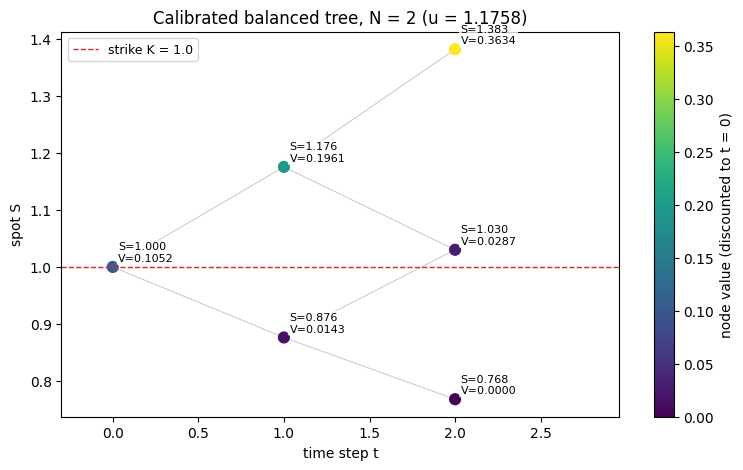

In [3]:
show(2)

**$N = 5$**: every node is labelled

N = 5: u = 1.097162, d = 0.923461, DF = 0.989794, root value = 0.105195
  t =  0: (S=1.0000, V=0.105195)
  t =  1: (S=0.9235, V=0.050070)  (S=1.0972, V=0.160320)
  t =  2: (S=0.8528, V=0.014997)  (S=1.0132, V=0.085144)  (S=1.2038, V=0.235497)
  t =  5: (S=0.6716, V=0.000000)  (S=0.7979, V=0.000000)  (S=0.9480, V=0.000000)
  t =  5: (S=1.1263, V=0.119973)  (S=1.3381, V=0.321234)  (S=1.5898, V=0.560351)
  (V_up + V_down)/2 at t = 1: 0.105195


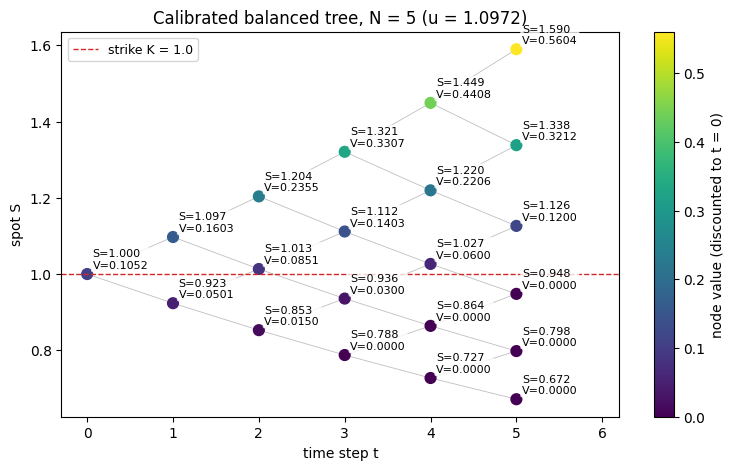

In [4]:
show(5)

**$N = 50$**: all 1326 nodes; labels on the important levels $t = 0, 25, 50$ (bottom, middle and top node); log scale

N = 50: u = 1.029196, d = 0.972857, DF = 0.998975, root value = 0.105195
  t =  0: (S=1.0000, V=0.105195)
  t =  1: (S=0.9729, V=0.087210)  (S=1.0292, V=0.123180)
  t = 25: (S=0.5026, V=0.000000)  (S=0.9877, V=0.060739)  (S=2.0533, V=1.051299)
  t = 50: (S=0.2526, V=0.000000)  (S=1.0320, V=0.030390)  (S=4.2160, V=3.055198)
  (V_up + V_down)/2 at t = 1: 0.105195


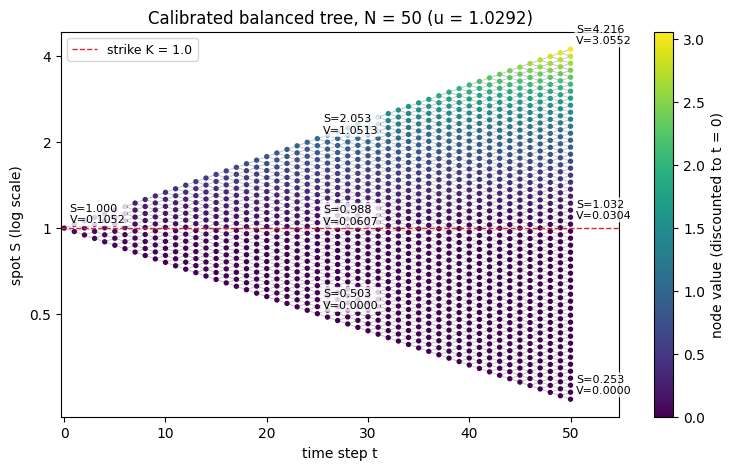

In [5]:
show(50)

**Result**: the root is the given price $0.105195$ for every $N$; each node is the average of its two children ($p_{up} = p_{down} = 1/2$); the leaves carry the payoff times $0.95$ ($DF^N = DF_1^{\,T}$); leaves below $K$ are worth 0.